# UTS Deep Learning — Task 2: Regression

Eksperimen ini bertujuan untuk mengembangkan model **Remaining Useful Life (RUL) Prediction** guna memperkirakan sisa siklus operasi mesin sebelum mengalami kegagalan berdasarkan data historis sensor dan parameter operasional.

Proses dilakukan melalui tahapan **Exploratory Data Analysis (EDA), data preprocessing, RUL labeling, sequence preparation, model development, training, dan evaluation**. Tiga model dibandingkan, yaitu Random Forest sebagai baseline serta GRU dan LSTM sebagai pendekatan Deep Learning. Evaluasi menggunakan RMSE, MAE, dan Asymmetric Score untuk menentukan model dengan performa terbaik.

Berdasarkan hasil eksperimen, **GRU terpilih sebagai model utama** dan dilatih ulang menggunakan seluruh data training untuk menghasilkan prediksi RUL pada data testing.

## 0. Setup

In [ ]:
!pip -q install scikit-learn pandas numpy matplotlib seaborn

### Penjelasan setup dan konfigurasi
Cell ini memuat pustaka untuk manipulasi data, visualisasi, preprocessing, pemodelan, dan evaluasi. Konfigurasi eksperimen seperti ukuran window, jumlah epoch, batch size, dropout, dan random seeds ditetapkan di sini. Perangkat komputasi yang terdeteksi (`cuda` atau `cpu`) menentukan apakah training berjalan menggunakan GPU atau CPU.

**Cara membaca output:** pastikan versi PyTorch dan perangkat komputasi tampil. Jika perangkat menunjukkan CPU, proses training dapat berjalan lebih lambat.

In [ ]:
import os, random, json, copy, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| PyTorch:", torch.__version__)

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

SEEDS = [42, 123, 2026]
RUL_CAP = 150
WINDOW_SIZE = 30
TRAIN_STRIDE = 5
BATCH_SIZE = 256
EPOCHS = 30
LEARNING_RATE = 1e-3
HIDDEN_SIZE = 64
DROPOUT = 0.20

Device: cuda | PyTorch: 2.14.1+cu130


## 1. Upload dataset secara manual

Upload file:
- `rul_train.csv.gz`
- `rul_test.csv.gz`
- `kamus_data.md`


### Mengunduh hasil eksperimen
Cell ini mengunduh CSV prediksi final dan ZIP artefak eksperimen dari sesi Colab ke perangkat lokal.

**Caption output:** pastikan kedua file berhasil terunduh dan disimpan. Notebook yang sudah dijalankan juga perlu diunduh terpisah melalui menu File → Download → Download .ipynb.

In [ ]:
from google.colab import files
uploaded = files.upload()
uploaded_names = list(uploaded.keys())
print("File di-upload:", uploaded_names)

def find_uploaded_file(keyword, extensions=(".csv.gz", ".csv")):
    matches = [name for name in uploaded_names
               if keyword.lower() in name.lower() and name.lower().endswith(extensions)]
    if not matches:
        raise FileNotFoundError(
            f"File dengan kata '{keyword}' tidak ditemukan. Upload file dataset yang sesuai."
        )
    return "/content/" + matches[0]

TRAIN_PATH = find_uploaded_file("train")
TEST_PATH = find_uploaded_file("test")
dict_matches = [n for n in uploaded_names if "kamus" in n.lower() or "dictionary" in n.lower()]
DICT_PATH = "/content/" + dict_matches[0] if dict_matches else None

print("TRAIN_PATH:", TRAIN_PATH)
print("TEST_PATH :", TEST_PATH)
print("DICT_PATH :", DICT_PATH)

Saving kamus_data.md to kamus_data.md
Saving rul_test.csv.gz to rul_test.csv.gz
Saving rul_train.csv.gz to rul_train.csv.gz
File di-upload: ['kamus_data.md', 'rul_test.csv.gz', 'rul_train.csv.gz']
TRAIN_PATH: /content/rul_train.csv.gz
TEST_PATH : /content/rul_test.csv.gz
DICT_PATH : /content/kamus_data.md


### Penjelasan pemuatan dataset
Kedua file dibaca menjadi DataFrame. Kompresi gzip digunakan otomatis untuk file berakhiran `.gz`. Pemeriksaan `shape` menunjukkan jumlah baris dan kolom; `head()` menampilkan contoh observasi untuk memastikan struktur kolom terbaca dengan benar.

**Caption output:** ukuran dataset training dan testing serta lima baris pertama digunakan untuk memverifikasi bahwa kolom identitas mesin, siklus, setting, dan sensor tersedia.

In [ ]:
train_df = pd.read_csv(TRAIN_PATH, compression="gzip" if TRAIN_PATH.endswith(".gz") else "infer")
test_df = pd.read_csv(TEST_PATH, compression="gzip" if TEST_PATH.endswith(".gz") else "infer")

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)
display(train_df.head())
display(test_df.head())

if DICT_PATH:
    with open(DICT_PATH, "r", encoding="utf-8") as f:
        print(f.read())

Train shape: (254174, 26)
Test shape : (51692, 26)


,id_unit,siklus,setel_1,setel_2,setel_3,s01,s02,s03,s04,s05,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,3,1,20.001,0.7005,100.0,1107.746,569.289,991.700,1099.533,NaN,...,1092.248,1144.779,1345.634,873.087,851.099,408.142,997.673,838.331,1012.076,439.003
1,3,2,34.996,0.8424,100.0,1071.040,587.821,1013.673,NaN,157.684,...,1095.511,1167.320,1340.661,871.230,791.396,398.338,980.601,814.985,1108.741,412.368
2,3,3,0.001,-0.0012,100.0,1130.132,585.094,998.221,1127.436,161.918,...,1091.245,1170.340,1330.785,872.114,807.389,388.304,938.802,847.512,1003.616,455.443
3,3,4,35.001,0.8375,100.0,1080.962,585.775,1016.998,1152.147,NaN,...,1096.911,1173.207,1348.423,877.459,784.038,399.505,978.649,813.737,1113.184,411.554
4,3,5,9.998,0.2483,100.0,1095.013,580.506,997.108,1119.245,169.359,...,1102.956,1159.881,1341.195,872.265,772.284,NaN,950.568,821.425,969.681,362.551


,id_unit,siklus,setel_1,setel_2,setel_3,s01,s02,s03,s04,s05,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,20.001,0.7025,100.0,1109.194,566.947,992.053,1101.107,173.988,...,1092.054,1134.754,1347.409,872.737,846.643,409.136,995.276,836.568,1012.850,437.922
1,1,2,9.998,0.2521,100.0,1091.159,578.471,1002.437,1123.170,169.325,...,1103.964,1153.523,1342.812,870.304,775.113,381.319,948.034,821.784,966.125,362.720
2,1,3,42.002,0.8370,100.0,1086.341,557.209,990.383,1139.700,162.133,...,1103.025,1192.780,1315.747,877.673,802.890,373.825,1020.731,841.189,1019.764,402.863
3,1,4,0.002,0.0004,100.0,1129.872,585.203,1004.457,1126.587,161.752,...,1091.025,1167.104,1332.974,870.364,802.731,388.525,939.540,846.664,1003.844,454.214
4,1,5,24.998,0.6178,60.0,1115.094,608.829,1043.742,1129.542,186.207,...,1105.461,1217.908,1368.876,877.994,789.337,383.327,1016.059,883.760,987.725,462.625


# Kamus data UTS Deep Learning

Semua kelompok menerima data yang sama. Label data uji tidak dibagikan.

## Tugas 1: klasifikasi_train.npz, klasifikasi_test.npz, klasifikasi_*_meta.csv

Satu sampel per unit produk dari pabrik komponen fiktif. Baris ke-i di berkas meta
memakai `indeks` = i pada array di berkas npz.

| Isi | Keterangan |
| --- | --- |
| `gambar` | Array uint8 (N, 64, 64), foto permukaan produk |
| `sensor` | Array float16 (N, 3, 128): suhu (C), getaran (relatif), arus (A) selama penekanan. NaN berarti data tidak terekam |
| id_unit | ID unit produk |
| lini | Lini produksi (A atau B) |
| shift | Shift produksi |
| id_mesin | Mesin penekan |
| batch_material | Batch bahan baku |
| kelas | Label: normal, gores, noda, retak, gelembung, las_dingin, kontaminasi. Hanya di data latih |

Label data latih berasal dari inspektur dan tidak dijamin bebas salah.

## Tugas 2: rul_train.csv.gz dan rul_test.csv.gz

Log per siklus untuk mesin press fiktif. Data latih berisi riwayat sampa

**Interpretasi hasil:** gunakan angka dan visualisasi yang tampil tepat di atas sebagai hasil aktual eksperimen. Jangan menyalin angka dari percobaan sebelumnya apabila hasil run ini berbeda.

## 2. Pemeriksaan data dan EDA

### Penjelasan struktur fitur
Cell ini memeriksa kolom wajib, mengidentifikasi sensor dengan pola nama `s` diikuti angka, dan menyusun daftar fitur setting serta sensor. Pemeriksaan ini mencegah proses berikutnya berjalan jika struktur data tidak sesuai.

**Caption output:** jumlah mesin, jumlah baris, jumlah sensor, dan jumlah fitur menunjukkan skala serta dimensi data yang dianalisis.

In [ ]:
required = ["id_unit", "siklus", "setel_1", "setel_2", "setel_3"]
missing = [c for c in required if c not in train_df.columns or c not in test_df.columns]
assert not missing, f"Kolom wajib tidak ditemukan: {missing}"

sensor_cols = sorted(
    [c for c in train_df.columns if c.startswith("s") and c[1:].isdigit()],
    key=lambda x: int(x[1:])
)
setting_cols = ["setel_1", "setel_2", "setel_3"]
feature_cols = setting_cols + sensor_cols
assert len(sensor_cols) > 0
assert set(feature_cols).issubset(test_df.columns)

print("Train machines:", train_df.id_unit.nunique(), "| rows:", len(train_df))
print("Test machines :", test_df.id_unit.nunique(), "| rows:", len(test_df))
print("Jumlah sensor:", len(sensor_cols))
print("Jumlah fitur:", len(feature_cols))

Train machines: 900 | rows: 254174
Test machines : 300 | rows: 51692
Jumlah sensor: 21
Jumlah fitur: 24


**Interpretasi hasil:** gunakan angka dan visualisasi yang tampil tepat di atas sebagai hasil aktual eksperimen. Jangan menyalin angka dari percobaan sebelumnya apabila hasil run ini berbeda.

### EDA: missing values dan panjang histori
Persentase missing value dihitung per fitur pada data training. Grafik pertama membantu menemukan sensor dengan data hilang. Histogram kedua menunjukkan variasi panjang histori operasi antar mesin.

**Caption output:** missing value yang relatif kecil tetap perlu ditangani sebelum training. Panjang histori yang berbeda menunjukkan bahwa setiap mesin memiliki jumlah siklus pengamatan yang tidak sama.

,missing_percent
s20,2.113
s02,2.074
s06,2.060
s18,2.060
s07,2.053
s04,2.052
s12,2.043
s09,2.035
s13,2.031
s19,2.029


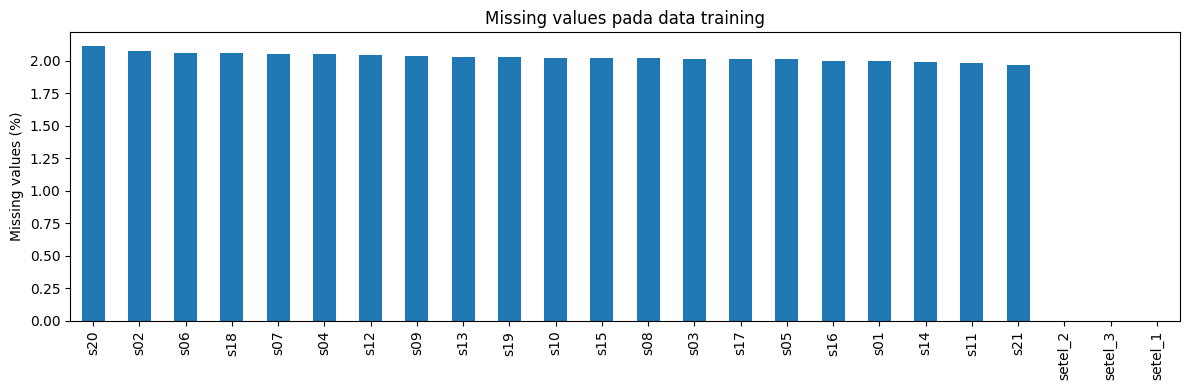

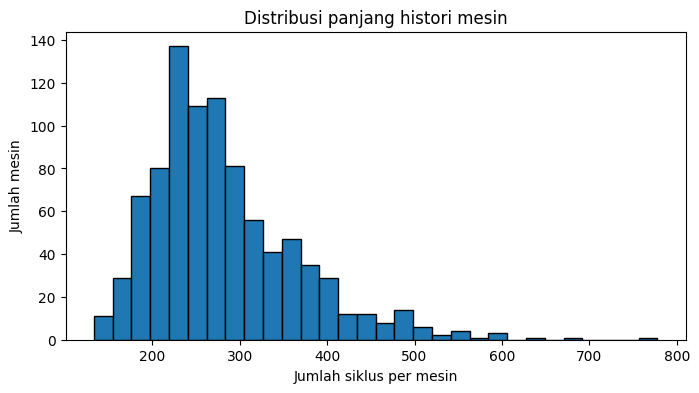

In [ ]:
missing_pct = train_df[feature_cols].isna().mean().mul(100).sort_values(ascending=False)
display(missing_pct.rename("missing_percent").to_frame().round(3))
plt.figure(figsize=(12,4))
missing_pct.plot(kind="bar")
plt.ylabel("Missing values (%)")
plt.title("Missing values pada data training")
plt.tight_layout()
plt.show()

train_lengths = train_df.groupby("id_unit")["siklus"].size()
plt.figure(figsize=(8,4))
plt.hist(train_lengths, bins=30, edgecolor="black")
plt.xlabel("Jumlah siklus per mesin")
plt.ylabel("Jumlah mesin")
plt.title("Distribusi panjang histori mesin")
plt.show()

### EDA: korelasi antarfitur
Heatmap korelasi dihitung dari sampel maksimal 20.000 baris agar komputasi lebih ringan. Nilai mendekati +1 menunjukkan hubungan linear positif, mendekati -1 menunjukkan hubungan negatif, dan mendekati 0 menunjukkan hubungan linear yang lemah.

**Caption output:** kelompok fitur dengan korelasi kuat dapat mengandung informasi yang mirip. Korelasi tidak otomatis menjadi alasan menghapus sensor karena model sequence masih dapat mempelajari hubungan temporal.

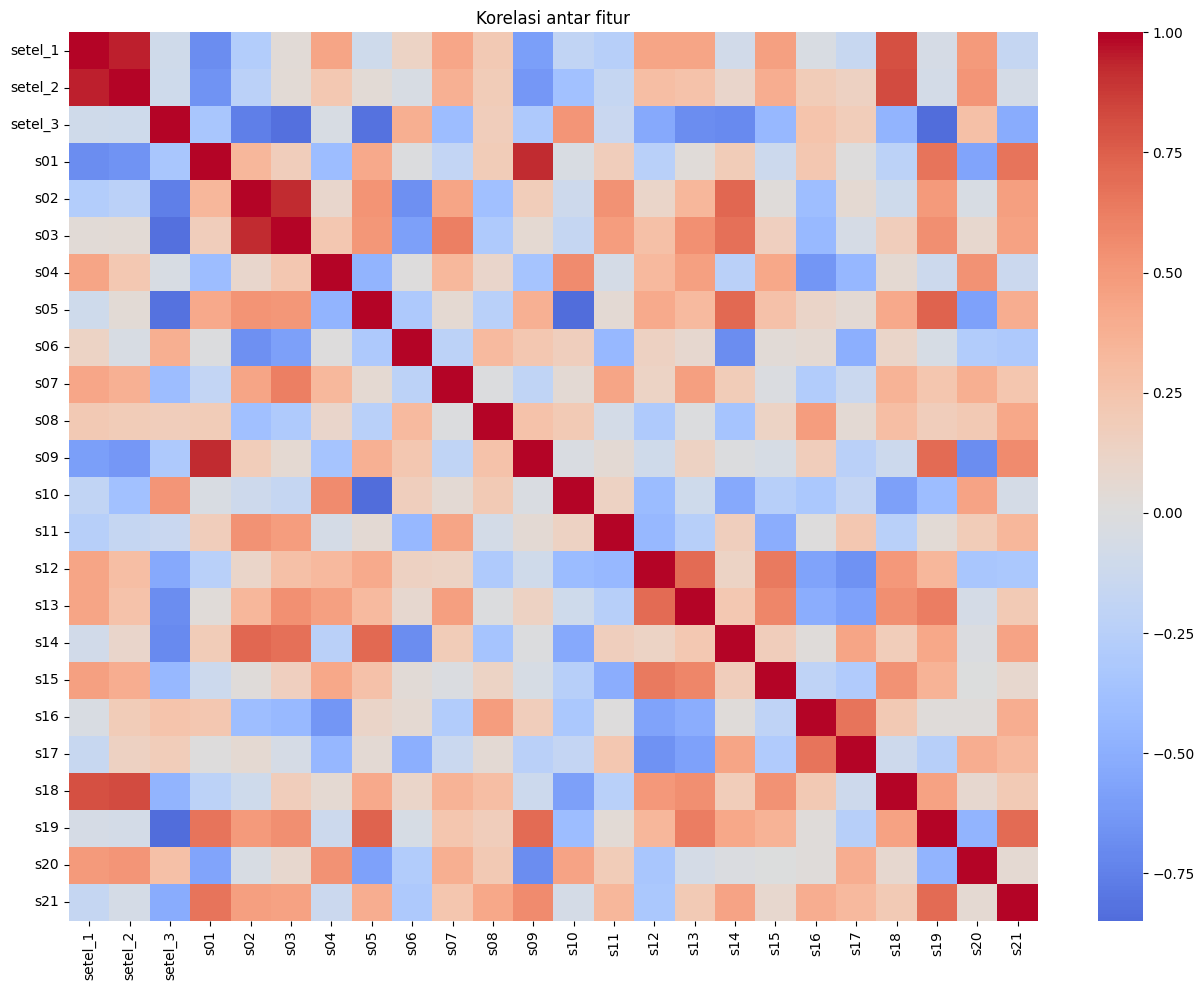

In [ ]:
corr = train_df[feature_cols].sample(min(20000, len(train_df)), random_state=42).corr()
plt.figure(figsize=(13,10))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Korelasi antar fitur")
plt.tight_layout()
plt.show()

## 3. Split berdasarkan mesin (menghindari data leakage)

### Pembagian training dan validation berdasarkan mesin
Identitas mesin dipisahkan menjadi 80% training dan 20% validation. Pemisahan dilakukan pada tingkat `id_unit`, bukan baris, agar siklus dari mesin yang sama tidak tersebar ke dua subset.

**Caption output:** jumlah mesin training dan validation serta pemeriksaan `isdisjoint` memastikan tidak ada identitas mesin yang tumpang tindih. Ini mengurangi risiko data leakage antar mesin.

In [ ]:
all_ids = train_df["id_unit"].drop_duplicates().to_numpy()
train_ids, val_ids = train_test_split(all_ids, test_size=0.20, random_state=42)

train_part = train_df[train_df.id_unit.isin(train_ids)].copy()
val_part = train_df[train_df.id_unit.isin(val_ids)].copy()
test_sorted = test_df.copy()

assert set(train_ids).isdisjoint(set(val_ids))
print("Train machines:", train_part.id_unit.nunique())
print("Validation machines:", val_part.id_unit.nunique())

Train machines: 720
Validation machines: 180


## 4. Label RUL dan preprocessing

Label training dihitung per mesin:

\[
RUL_i(t)=\min(T_i-t,150)
\]

dengan \(T_i\) sebagai siklus terakhir/failure cycle mesin ke-i. Imputer dan scaler hanya di-fit pada bagian training split, lalu diterapkan ke validation dan test.

### Pembentukan target Remaining Useful Life (RUL)
Untuk setiap mesin, siklus maksimum dianggap sebagai siklus failure pada data training. Label dihitung sebagai selisih antara siklus failure dan siklus pengamatan, kemudian dibatasi maksimum 150 siklus (*RUL capping*).

**Caption output:** histogram label memperlihatkan distribusi target. Penumpukan pada 150 merupakan akibat capping, bukan kesalahan pembacaan data.

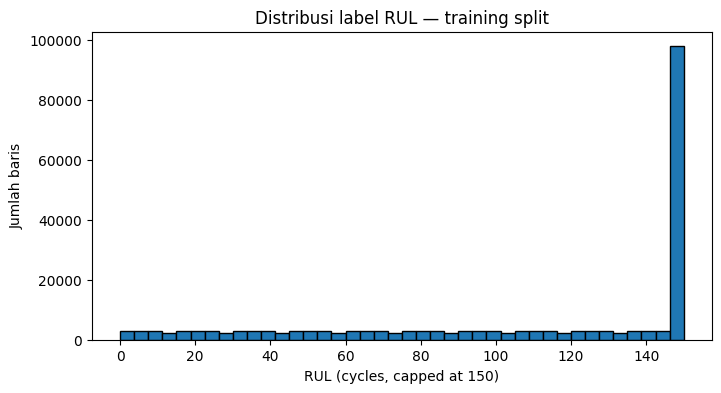

In [ ]:
def add_rul_labels(df, cap=150):
    out = df.copy()
    last_cycle = out.groupby("id_unit")["siklus"].transform("max")
    out["rul"] = (last_cycle - out["siklus"]).clip(lower=0, upper=cap)
    return out

train_part = add_rul_labels(train_part, RUL_CAP)
val_part = add_rul_labels(val_part, RUL_CAP)

plt.figure(figsize=(8,4))
plt.hist(train_part["rul"], bins=40, edgecolor="black")
plt.xlabel("RUL (cycles, capped at 150)")
plt.ylabel("Jumlah baris")
plt.title("Distribusi label RUL — training split")
plt.show()

### Imputasi, seleksi fitur konstan, dan standardisasi
Data diurutkan berdasarkan identitas mesin dan siklus. Median imputer dan StandardScaler di-fit hanya pada training split, lalu transformasi yang sama diterapkan ke validation dan test. Fitur dengan variasi nol dibuang karena tidak memberikan informasi pembeda.

**Caption output:** jumlah fitur terpilih dan ukuran array hasil transformasi memastikan data numerik siap dibentuk menjadi sequence. Melakukan fit preprocessing hanya pada training membantu mencegah data leakage.

In [ ]:
for df in [train_part, val_part, test_sorted]:
    df.sort_values(["id_unit", "siklus"], inplace=True)
    df.reset_index(drop=True, inplace=True)

usable_features = [c for c in feature_cols if train_part[c].notna().any()]
imputer = SimpleImputer(strategy="median")
Xtr_imp_all = imputer.fit_transform(train_part[usable_features])

stds = Xtr_imp_all.std(axis=0)
keep_mask = stds > 1e-8
selected_features = [c for c, keep in zip(usable_features, keep_mask) if keep]
Xtr_imp = Xtr_imp_all[:, keep_mask]

scaler = StandardScaler()
scaler.fit(Xtr_imp)

def transform_features(df):
    arr = imputer.transform(df[usable_features])[:, keep_mask]
    arr = scaler.transform(arr).astype(np.float32)
    return arr

X_train_rows = transform_features(train_part)
X_val_rows = transform_features(val_part)
X_test_rows = transform_features(test_sorted)

print("Selected features:", len(selected_features), selected_features)
print("Transformed shapes:", X_train_rows.shape, X_val_rows.shape, X_test_rows.shape)

Selected features: 24 ['setel_1', 'setel_2', 'setel_3', 's01', 's02', 's03', 's04', 's05', 's06', 's07', 's08', 's09', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's18', 's19', 's20', 's21']
Transformed shapes: (203784, 24) (50390, 24) (51692, 24)


## 5. Membentuk sequence

### Pembentukan sequence untuk model time series
Model GRU dan LSTM menerima potongan histori sepanjang 30 siklus. Training menggunakan sliding window dengan stride 5; target setiap sequence adalah RUL pada titik akhir window. Validation mengambil satu titik pengamatan acak sebelum failure untuk setiap mesin, sehingga target validation menyerupai kondisi test.

**Caption output:** jumlah sequence training, validation, dan test menunjukkan banyaknya contoh yang masuk ke model. Validation dan test masing-masing menggunakan satu sequence akhir per mesin.

In [ ]:
def make_train_sequences(df, feature_array, window_size=WINDOW_SIZE, stride=TRAIN_STRIDE):
    X_list, y_list, machine_list = [], [], []
    for machine_id, group in df.groupby("id_unit", sort=False):
        idx = group.index.to_numpy()
        x_machine = feature_array[idx]
        y_machine = group["rul"].to_numpy(dtype=np.float32)
        if len(x_machine) < window_size:
            continue
        starts = list(range(0, len(x_machine)-window_size+1, stride))
        last_start = len(x_machine)-window_size
        if starts[-1] != last_start:
            starts.append(last_start)
        for start in starts:
            end = start + window_size
            X_list.append(x_machine[start:end])
            y_list.append(y_machine[end-1])
            machine_list.append(machine_id)
    return (np.asarray(X_list, dtype=np.float32),
            np.asarray(y_list, dtype=np.float32),
            np.asarray(machine_list))

def make_validation_last_sequences(df, feature_array, window_size=WINDOW_SIZE, seed=2026):
    """
    Membentuk satu contoh validation per mesin dari histori yang dipotong
    SEBELUM failure. Siklus failure tidak pernah menjadi titik prediksi.

    Mesin dengan histori kurang dari 2 baris tidak dapat digunakan karena
    tidak ada titik potong sebelum failure; mesin tersebut dilewati.
    """
    rng = np.random.default_rng(seed)
    X_list, y_list, ids = [], [], []

    for machine_id, group in df.groupby("id_unit", sort=False):
        idx = group.index.to_numpy()
        x = feature_array[idx]
        cycles = group["siklus"].to_numpy()
        failure_cycle = cycles.max()

        # Harus ada minimal satu observasi sebelum failure.
        if len(x) < 2:
            continue

        # Pilih indeks akhir histori dari 0 sampai len(x)-2.
        # Dengan demikian, end_idx selalu sebelum baris failure terakhir.
        if len(x) >= window_size:
            end_idx = int(rng.integers(window_size - 1, len(x) - 1))
            seq = x[end_idx - window_size + 1:end_idx + 1]
        else:
            end_idx = int(rng.integers(0, len(x) - 1))
            history = x[:end_idx + 1]
            pad = np.repeat(history[:1], window_size - len(history), axis=0)
            seq = np.concatenate([pad, history], axis=0)

        target = min(float(failure_cycle - cycles[end_idx]), RUL_CAP)
        if target <= 0:
            raise ValueError(
                f"Validation target harus positif untuk mesin {machine_id}; "
                "periksa urutan siklus dan definisi failure cycle."
            )

        X_list.append(seq)
        y_list.append(target)
        ids.append(machine_id)

    return (
        np.asarray(X_list, dtype=np.float32),
        np.asarray(y_list, dtype=np.float32),
        np.asarray(ids)
    )

def make_last_test_sequences(df, feature_array, window_size=WINDOW_SIZE):
    X_list, ids = [], []
    for machine_id, group in df.groupby("id_unit", sort=False):
        idx = group.index.to_numpy()
        x = feature_array[idx]
        if len(x) >= window_size:
            seq = x[-window_size:]
        else:
            pad = np.repeat(x[:1], window_size-len(x), axis=0)
            seq = np.concatenate([pad, x], axis=0)
        X_list.append(seq); ids.append(machine_id)
    return np.asarray(X_list, np.float32), np.asarray(ids)

X_seq_train, y_seq_train, group_train = make_train_sequences(train_part, X_train_rows)
X_seq_val, y_seq_val, val_machine_ids = make_validation_last_sequences(val_part, X_val_rows)
X_seq_test, test_machine_ids = make_last_test_sequences(test_sorted, X_test_rows)

print("Train sequences:", X_seq_train.shape)
print("Validation final sequences:", X_seq_val.shape)
print("Test final sequences:", X_seq_test.shape)

Train sequences: (37435, 30, 24)
Validation final sequences: (180, 30, 24)
Test final sequences: (300, 30, 24)


## 6. Metrik evaluasi

Asymmetric Score mengikuti rumus pada instruksi tugas. Definisikan \(d=\hat{y}-y\):

\[
S(d)=\begin{cases}
e^{-d/13}-1,&d<0\\
e^{d/10}-1,&d\geq0
\end{cases}
\]

Notebook melaporkan jumlah skor dan rata-rata skor. Rata-rata digunakan untuk memudahkan perbandingan ketika jumlah sampel berbeda.

### Definisi metrik evaluasi
Selain RMSE dan MAE, digunakan Asymmetric Score sesuai rumus tugas. Penalti bergantung pada arah dan besar selisih prediksi terhadap RUL aktual. Fungsi ini mengembalikan jumlah skor dan rata-rata skor agar hasil dapat dibandingkan.

**Catatan interpretasi:** semakin rendah RMSE, MAE, dan Asymmetric Score, semakin baik hasil prediksi menurut metrik tersebut.

In [ ]:
def asymmetric_score(y_true, y_pred):
    d = np.asarray(y_pred) - np.asarray(y_true)
    exponent = np.where(d < 0, -d/13.0, d/10.0)
    exponent = np.clip(exponent, 0, 700)
    scores = np.exp(exponent) - 1
    return float(np.sum(scores)), float(np.mean(scores))

def calculate_metrics(y_true, y_pred):
    y_pred = np.clip(np.asarray(y_pred), 0, RUL_CAP)
    total_asym, mean_asym = asymmetric_score(y_true, y_pred)
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "Asymmetric_Score_Sum": total_asym,
        "Asymmetric_Score_Mean": mean_asym
    }

RUL_BINS = [0, 30, 60, 100, 150.0001]
RUL_LABELS = ["0-30", "31-60", "61-100", "101-150"]

def metrics_by_rul_range(y_true, y_pred, model_name):
    y_true = np.asarray(y_true)
    y_pred = np.clip(np.asarray(y_pred), 0, RUL_CAP)
    bins = pd.cut(y_true, bins=RUL_BINS, labels=RUL_LABELS, include_lowest=True)
    rows = []
    for label in RUL_LABELS:
        mask = np.asarray(bins == label)
        if mask.sum() == 0:
            rows.append({"model": model_name, "RUL_range": label, "n": 0,
                         "RMSE": np.nan, "MAE": np.nan,
                         "Asymmetric_Score_Mean": np.nan})
        else:
            m = calculate_metrics(y_true[mask], y_pred[mask])
            rows.append({"model": model_name, "RUL_range": label, "n": int(mask.sum()),
                         "RMSE": m["RMSE"], "MAE": m["MAE"],
                         "Asymmetric_Score_Mean": m["Asymmetric_Score_Mean"]})
    return rows

## 7. Random Forest baseline

### Baseline Random Forest
Random Forest tidak memproses urutan mentah seperti GRU/LSTM. Setiap window diringkas menjadi fitur statistik: rata-rata, standar deviasi, minimum, maksimum, dan nilai pada siklus terakhir. Model ini menjadi pembanding non-Deep Learning.

**Caption output:** metrik validation Random Forest menjadi baseline untuk menilai apakah model sequence Deep Learning memberikan peningkatan.

In [ ]:
def window_to_stats(X):
    return np.concatenate([
        X.mean(axis=1), X.std(axis=1), X.min(axis=1),
        X.max(axis=1), X[:, -1, :]
    ], axis=1)

X_rf_train = window_to_stats(X_seq_train)
X_rf_val = window_to_stats(X_seq_val)

rf = RandomForestRegressor(
    n_estimators=250, min_samples_leaf=2,
    random_state=42, n_jobs=-1
)
rf.fit(X_rf_train, y_seq_train)
rf_val_pred = np.clip(rf.predict(X_rf_val), 0, RUL_CAP)
rf_metrics = calculate_metrics(y_seq_val, rf_val_pred)
print(rf_metrics)

{'RMSE': 26.39703870023803, 'MAE': 20.08644133477633, 'Asymmetric_Score_Sum': 14860.392909272134, 'Asymmetric_Score_Mean': 82.55773838484518}


**Interpretasi hasil:** gunakan angka dan visualisasi yang tampil tepat di atas sebagai hasil aktual eksperimen. Jangan menyalin angka dari percobaan sebelumnya apabila hasil run ini berbeda.

## 8. Arsitektur GRU dan LSTM

### Dataset PyTorch dan arsitektur sequence
Class `SequenceDataset` mengubah array menjadi tensor PyTorch. `RULNet` menggunakan GRU atau LSTM satu lapis, kemudian hidden state terakhir diteruskan ke dense head untuk menghasilkan satu nilai RUL. Dropout digunakan sebagai regularisasi.

**Catatan:** arsitektur GRU dan LSTM dibuat sebanding agar perbedaan hasil terutama mencerminkan jenis recurrent layer.

In [ ]:
class SequenceDataset(Dataset):
    def __init__(self, X, y=None):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = None if y is None else torch.tensor(y, dtype=torch.float32).view(-1, 1)
    def __len__(self): return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx] if self.y is None else (self.X[idx], self.y[idx])

class RULNet(nn.Module):
    def __init__(self, input_size, kind="GRU", hidden_size=64, dropout=0.2):
        super().__init__()
        rnn_cls = nn.GRU if kind.upper() == "GRU" else nn.LSTM
        self.rnn = rnn_cls(input_size, hidden_size, num_layers=1, batch_first=True)
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1, :])

def predict_dl(model, X):
    model.eval()
    loader = DataLoader(SequenceDataset(X), batch_size=BATCH_SIZE, shuffle=False)
    preds = []
    with torch.no_grad():
        for xb in loader:
            preds.extend(model(xb.to(DEVICE)).cpu().numpy().ravel())
    return np.clip(np.asarray(preds), 0, RUL_CAP)

## 9. Eksperimen tiga random seeds

Setiap arsitektur Deep Learning dijalankan dengan seed 42, 123, dan 2026. Checkpoint terbaik dipilih berdasarkan validation RMSE masing-masing run. Tabel ringkasan akan menampilkan rata-rata dan standar deviasi antar-seed.

### Training GRU dan LSTM dengan tiga random seeds
Setiap arsitektur dilatih tiga kali menggunakan seed 42, 123, dan 2026. Pada setiap run, checkpoint dengan validation RMSE terendah disimpan. Pengulangan ini membantu mengukur sensitivitas hasil terhadap inisialisasi dan pengacakan training.

**Caption output:** log epoch menunjukkan perkembangan validation RMSE. Tabel hasil per seed merangkum epoch terbaik, RMSE, MAE, dan Asymmetric Score untuk setiap run.

In [ ]:
train_loader = DataLoader(
    SequenceDataset(X_seq_train, y_seq_train),
    batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
val_loader = DataLoader(
    SequenceDataset(X_seq_val, y_seq_val),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

def train_one_run(kind, seed, epochs=EPOCHS):
    seed_everything(seed)
    model = RULNet(X_seq_train.shape[-1], kind, HIDDEN_SIZE, DROPOUT).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.MSELoss()
    best_rmse, best_epoch, best_state = float("inf"), None, None
    history = {"train_loss": [], "val_rmse": []}

    for epoch in range(epochs):
        model.train()
        batch_losses = []
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            batch_losses.append(loss.item())

        val_pred = predict_dl(model, X_seq_val)
        val_rmse = float(np.sqrt(mean_squared_error(y_seq_val, val_pred)))
        history["train_loss"].append(float(np.mean(batch_losses)))
        history["val_rmse"].append(val_rmse)
        if val_rmse < best_rmse:
            best_rmse, best_epoch = val_rmse, epoch + 1
            best_state = copy.deepcopy(model.state_dict())

        if (epoch + 1) % 5 == 0:
            print(f"{kind} seed={seed} epoch={epoch+1}/{epochs} val_RMSE={val_rmse:.3f}")

    model.load_state_dict(best_state)
    pred = predict_dl(model, X_seq_val)
    return model, pred, best_rmse, best_epoch, history

runs = {}
run_rows = []
for kind in ["GRU", "LSTM"]:
    for seed in SEEDS:
        print(f"\n===== {kind} | seed {seed} =====")
        model, pred, best_rmse, best_epoch, history = train_one_run(kind, seed)
        runs[(kind, seed)] = {
            "model": model, "pred": pred, "best_rmse": best_rmse,
            "best_epoch": best_epoch, "history": history
        }
        met = calculate_metrics(y_seq_val, pred)
        run_rows.append({
            "model": kind, "seed": seed, "best_epoch": best_epoch,
            **met
        })

runs_df = pd.DataFrame(run_rows)
display(runs_df)


===== GRU | seed 42 =====
GRU seed=42 epoch=5/30 val_RMSE=25.180
GRU seed=42 epoch=10/30 val_RMSE=23.587
GRU seed=42 epoch=15/30 val_RMSE=22.675
GRU seed=42 epoch=20/30 val_RMSE=23.373
GRU seed=42 epoch=25/30 val_RMSE=23.639
GRU seed=42 epoch=30/30 val_RMSE=23.406

===== GRU | seed 123 =====
GRU seed=123 epoch=5/30 val_RMSE=26.361
GRU seed=123 epoch=10/30 val_RMSE=24.690
GRU seed=123 epoch=15/30 val_RMSE=23.997
GRU seed=123 epoch=20/30 val_RMSE=23.994
GRU seed=123 epoch=25/30 val_RMSE=24.021
GRU seed=123 epoch=30/30 val_RMSE=23.656

===== GRU | seed 2026 =====
GRU seed=2026 epoch=5/30 val_RMSE=25.220
GRU seed=2026 epoch=10/30 val_RMSE=24.369
GRU seed=2026 epoch=15/30 val_RMSE=23.005
GRU seed=2026 epoch=20/30 val_RMSE=23.278
GRU seed=2026 epoch=25/30 val_RMSE=22.904
GRU seed=2026 epoch=30/30 val_RMSE=23.579

===== LSTM | seed 42 =====
LSTM seed=42 epoch=5/30 val_RMSE=25.763
LSTM seed=42 epoch=10/30 val_RMSE=25.129
LSTM seed=42 epoch=15/30 val_RMSE=24.331
LSTM seed=42 epoch=20/30 val_RM

,model,seed,best_epoch,RMSE,MAE,Asymmetric_Score_Sum,Asymmetric_Score_Mean
0,GRU,42,19,22.607177,17.871939,4475.565430,24.864252
1,GRU,123,23,22.773974,17.726635,4822.707031,26.792816
2,GRU,2026,24,22.291184,17.726349,3304.901855,18.360565
3,LSTM,42,25,22.950273,18.086914,5124.639648,28.470221
4,LSTM,123,30,22.908880,18.117451,5040.659180,28.003662
5,LSTM,2026,17,22.912494,18.125515,4487.880371,24.932669


### Ringkasan variasi antar-seed
Rata-rata dan standar deviasi dihitung dari tiga run untuk masing-masing arsitektur. Rata-rata menggambarkan performa umum, sedangkan standar deviasi menunjukkan variasi hasil antar-seed.

**Caption output:** model dengan mean RMSE lebih rendah memiliki error kuadrat rata-rata yang lebih kecil. Standar deviasi yang lebih rendah menunjukkan hasil antar-run lebih stabil.

,model,RMSE_mean,RMSE_std,MAE_mean,MAE_std,Asymmetric_Score_Mean_mean,Asymmetric_Score_Mean_std,best_epoch_median
0,GRU,22.5574,0.2452,17.775,0.0840,23.3392,4.4181,23
1,LSTM,22.9239,0.0229,18.110,0.0204,27.1355,1.9219,25


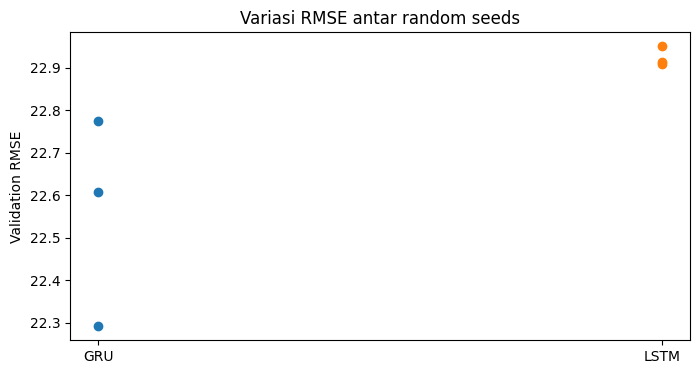

In [ ]:
summary_rows = []
for kind, group in runs_df.groupby("model"):
    row = {"model": kind}
    for metric in ["RMSE", "MAE", "Asymmetric_Score_Mean"]:
        row[metric+"_mean"] = group[metric].mean()
        row[metric+"_std"] = group[metric].std(ddof=1)
    row["best_epoch_median"] = int(group["best_epoch"].median())
    summary_rows.append(row)
seed_summary = pd.DataFrame(summary_rows)
display(seed_summary.round(4))

plt.figure(figsize=(8,4))
for kind in ["GRU", "LSTM"]:
    vals = runs_df[runs_df.model == kind]["RMSE"]
    plt.scatter([kind]*len(vals), vals, label=kind)
plt.ylabel("Validation RMSE")
plt.title("Variasi RMSE antar random seeds")
plt.show()

## 10. Evaluasi rata-rata prediksi antar-seed dan per rentang RUL

Untuk analisis per rentang RUL, prediksi tiga run pada arsitektur yang sama dirata-ratakan terlebih dahulu. Ini menghasilkan satu prediksi ensemble sederhana untuk masing-masing arsitektur dan membuat perbandingan rentang RUL lebih stabil.

### Evaluasi keseluruhan dan per rentang RUL
Prediksi dari tiga seed pada arsitektur yang sama dirata-ratakan terlebih dahulu. Metrik keseluruhan kemudian dihitung pada seluruh mesin validation, sedangkan evaluasi per rentang mengelompokkan sampel berdasarkan RUL aktual: 0–30, 31–60, 61–100, dan 101–150.

**Caption output:** tabel keseluruhan membandingkan Random Forest, GRU, dan LSTM. Tabel per rentang menunjukkan pada kondisi umur mesin mana model paling sulit atau paling mudah memprediksi.

In [ ]:
mean_preds = {}
overall_rows = [{"model": "Random Forest", **rf_metrics}]
range_rows = metrics_by_rul_range(y_seq_val, rf_val_pred, "Random Forest")

for kind in ["GRU", "LSTM"]:
    pred_stack = np.vstack([runs[(kind, seed)]["pred"] for seed in SEEDS])
    mean_pred = pred_stack.mean(axis=0)
    mean_preds[kind] = mean_pred
    overall_rows.append({"model": kind, **calculate_metrics(y_seq_val, mean_pred)})
    range_rows.extend(metrics_by_rul_range(y_seq_val, mean_pred, kind))

overall_df = pd.DataFrame(overall_rows).sort_values("RMSE")
range_df = pd.DataFrame(range_rows)
print("Metrik keseluruhan:")
display(overall_df.round(4))
print("Metrik per rentang RUL:")
display(range_df.round(4))

Metrik keseluruhan:


,model,RMSE,MAE,Asymmetric_Score_Sum,Asymmetric_Score_Mean
1,GRU,22.3685,17.6606,3983.6001,22.1311
2,LSTM,22.7171,17.9710,4749.9912,26.3888
0,Random Forest,26.3970,20.0864,14860.3929,82.5577


Metrik per rentang RUL:


,model,RUL_range,n,RMSE,MAE,Asymmetric_Score_Mean
0,Random Forest,0-30,23,21.1297,16.9228,12.7997
1,Random Forest,31-60,20,32.0832,22.9790,213.6749
2,Random Forest,61-100,34,43.6166,37.5408,290.8253
3,Random Forest,101-150,103,17.0344,14.4696,3.9266
4,GRU,0-30,23,10.7128,9.0804,1.9466
5,GRU,31-60,20,24.9425,18.6844,33.1800
6,GRU,61-100,34,36.1679,31.5955,83.0817
7,GRU,101-150,103,17.2094,14.7779,4.3733
8,LSTM,0-30,23,11.5013,9.5351,2.1809
9,LSTM,31-60,20,24.0294,18.2301,27.8318


### Visualisasi hasil prediksi
Grafik kiri membandingkan RUL aktual dengan prediksi; garis diagonal merepresentasikan prediksi sempurna. Titik yang semakin dekat dengan garis menunjukkan error yang lebih kecil. Grafik kanan memperlihatkan RMSE pada tiap kelompok RUL.

**Caption output:** penyebaran titik dan perubahan RMSE antar rentang membantu mengidentifikasi pola error yang tidak terlihat dari satu angka metrik keseluruhan.

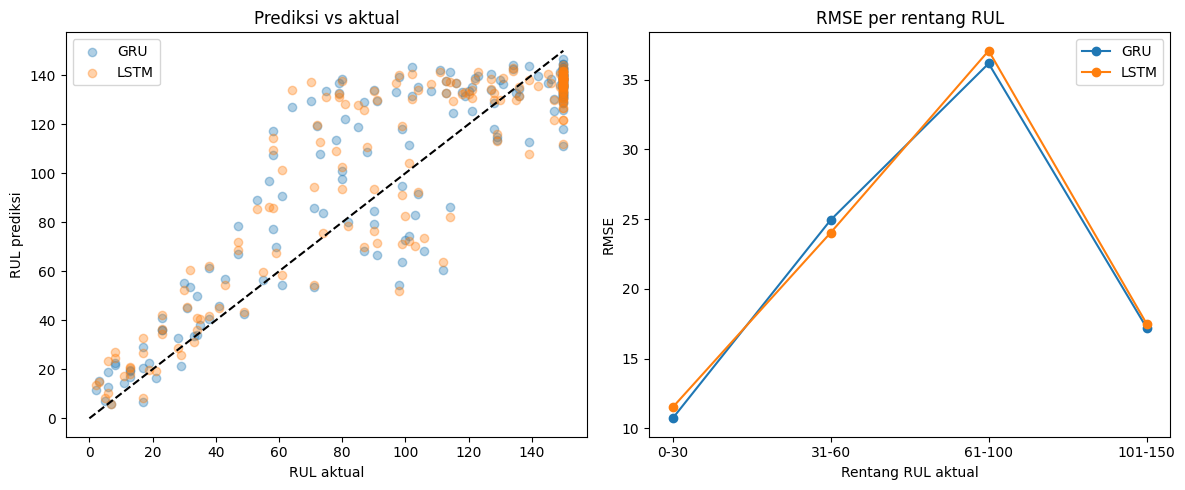

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))
for kind in ["GRU", "LSTM"]:
    axes[0].scatter(y_seq_val, mean_preds[kind], alpha=0.35, label=kind)
axes[0].plot([0,150],[0,150],"k--")
axes[0].set(xlabel="RUL aktual", ylabel="RUL prediksi", title="Prediksi vs aktual")
axes[0].legend()

for kind in ["GRU", "LSTM"]:
    sub = range_df[range_df.model == kind]
    axes[1].plot(sub.RUL_range.astype(str), sub.RMSE, marker="o", label=kind)
axes[1].set(xlabel="Rentang RUL aktual", ylabel="RMSE", title="RMSE per rentang RUL")
axes[1].legend()
plt.tight_layout()
plt.show()

## 11. Pilih arsitektur utama

Pemilihan arsitektur utama menggunakan rata-rata validation RMSE antar tiga seed. Asymmetric Score tetap dilaporkan sebagai metrik tambahan agar trade-off kesalahan prediksi tidak diabaikan. Random Forest tetap menjadi baseline, bukan kandidat model Deep Learning utama.

### Pemilihan arsitektur utama
GRU atau LSTM dipilih berdasarkan rata-rata validation RMSE dari tiga seed. Random Forest tidak menjadi kandidat model utama karena perannya adalah baseline non-Deep Learning. Asymmetric Score tetap dilaporkan sebagai metrik tambahan.

**Caption output:** nama arsitektur terpilih dan median best epoch digunakan sebagai dasar konfigurasi retraining final.

In [ ]:
dl_summary = seed_summary.sort_values("RMSE_mean")
SELECTED_ARCH = dl_summary.iloc[0]["model"]
FINAL_EPOCHS = int(dl_summary.loc[dl_summary.model == SELECTED_ARCH, "best_epoch_median"].iloc[0])
print("Arsitektur Deep Learning terpilih berdasarkan mean RMSE:", SELECTED_ARCH)
print("Epoch retraining final (median best epoch):", FINAL_EPOCHS)

Arsitektur Deep Learning terpilih berdasarkan mean RMSE: GRU
Epoch retraining final (median best epoch): 23


## 12. Retraining model terpilih dengan seluruh 900 mesin training

Setelah arsitektur dan jumlah epoch dipilih dari eksperimen train/validation, preprocessing di-fit ulang pada seluruh data training. Model final kemudian dilatih menggunakan seluruh sequence training. Validation set tidak digabungkan untuk memilih parameter lagi setelah keputusan model dibuat.

### Persiapan retraining final
Setelah arsitektur dipilih, label RUL dihitung ulang untuk seluruh 900 mesin training. Imputer dan scaler di-fit ulang pada seluruh data training, kemudian sequence training dan sequence test dibentuk dengan konfigurasi yang sama.

**Caption output:** jumlah sequence final dan sequence test memastikan model final menggunakan seluruh data training yang tersedia dan satu sequence untuk setiap mesin test.

In [ ]:
# Label RUL untuk seluruh training data
full_train = add_rul_labels(train_df.copy(), RUL_CAP)
full_train.sort_values(["id_unit", "siklus"], inplace=True)
full_train.reset_index(drop=True, inplace=True)
test_sorted = test_df.copy().sort_values(["id_unit", "siklus"]).reset_index(drop=True)

# Refit preprocessing hanya pada seluruh training data
full_usable_features = [c for c in feature_cols if full_train[c].notna().any()]
final_imputer = SimpleImputer(strategy="median")
X_full_imp_all = final_imputer.fit_transform(full_train[full_usable_features])
final_stds = X_full_imp_all.std(axis=0)
final_keep_mask = final_stds > 1e-8
final_selected_features = [c for c, keep in zip(full_usable_features, final_keep_mask) if keep]
X_full_imp = X_full_imp_all[:, final_keep_mask]

final_scaler = StandardScaler()
X_full_rows = final_scaler.fit_transform(X_full_imp).astype(np.float32)

def final_transform(df):
    arr = final_imputer.transform(df[full_usable_features])[:, final_keep_mask]
    return final_scaler.transform(arr).astype(np.float32)

X_test_final_rows = final_transform(test_sorted)
X_full_seq, y_full_seq, full_group = make_train_sequences(
    full_train, X_full_rows, WINDOW_SIZE, TRAIN_STRIDE
)
X_test_final, final_test_ids = make_last_test_sequences(
    test_sorted, X_test_final_rows, WINDOW_SIZE
)
print("Full training sequences:", X_full_seq.shape)
print("Final test sequences:", X_test_final.shape)

Full training sequences: (46680, 30, 24)
Final test sequences: (300, 30, 24)


### Retraining model final
Model terpilih dilatih ulang menggunakan seluruh sequence training. Jumlah epoch ditetapkan berdasarkan median best epoch dari eksperimen validation. Karena seluruh data training digunakan, tidak ada validation set terpisah pada tahap retraining final.

**Caption output:** training loss memperlihatkan penurunan error pada data yang digunakan untuk melatih model final. Kurva ini bukan estimasi performa generalisasi; performa model dibandingkan menggunakan hasil validation sebelum retraining.

Final GRU epoch 1/23 | loss=9505.4500
Final GRU epoch 2/23 | loss=2187.6183
Final GRU epoch 3/23 | loss=716.8866
Final GRU epoch 4/23 | loss=691.7876
Final GRU epoch 5/23 | loss=675.4881
Final GRU epoch 6/23 | loss=669.6809
Final GRU epoch 7/23 | loss=647.9077
Final GRU epoch 8/23 | loss=622.8321
Final GRU epoch 9/23 | loss=616.4094
Final GRU epoch 10/23 | loss=600.0368
Final GRU epoch 11/23 | loss=594.3147
Final GRU epoch 12/23 | loss=589.0360
Final GRU epoch 13/23 | loss=583.0325
Final GRU epoch 14/23 | loss=572.2215
Final GRU epoch 15/23 | loss=574.9515
Final GRU epoch 16/23 | loss=568.5573
Final GRU epoch 17/23 | loss=572.4529
Final GRU epoch 18/23 | loss=569.6323
Final GRU epoch 19/23 | loss=563.8982
Final GRU epoch 20/23 | loss=561.2924
Final GRU epoch 21/23 | loss=554.4624
Final GRU epoch 22/23 | loss=553.9697
Final GRU epoch 23/23 | loss=556.2296


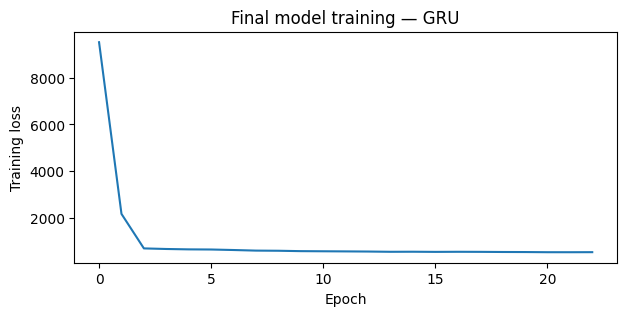

In [ ]:
seed_everything(2026)
final_model = RULNet(
    input_size=X_full_seq.shape[-1],
    kind=SELECTED_ARCH,
    hidden_size=HIDDEN_SIZE,
    dropout=DROPOUT
).to(DEVICE)

full_loader = DataLoader(
    SequenceDataset(X_full_seq, y_full_seq),
    batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
optimizer = torch.optim.Adam(final_model.parameters(), lr=LEARNING_RATE)
criterion = nn.MSELoss()
final_losses = []

for epoch in range(FINAL_EPOCHS):
    final_model.train()
    losses = []
    for xb, yb in full_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(final_model(xb), yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(final_model.parameters(), 1.0)
        optimizer.step()
        losses.append(loss.item())
    final_losses.append(float(np.mean(losses)))
    print(f"Final {SELECTED_ARCH} epoch {epoch+1}/{FINAL_EPOCHS} | loss={np.mean(losses):.4f}")

plt.figure(figsize=(7,3))
plt.plot(final_losses)
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title(f"Final model training — {SELECTED_ARCH}")
plt.show()

## 13. Prediksi test dan ekspor file

### Inferensi pada data test
Model final menghasilkan satu prediksi RUL untuk setiap mesin test berdasarkan 30 siklus terakhir yang tersedia. Nilai prediksi dibatasi pada rentang 0–150 dan disimpan bersama identitas mesin.

**Caption output:** pemeriksaan jumlah baris, keunikan `id_unit`, missing value, serta batas RUL memastikan file prediksi memiliki format yang diharapkan. Akurasi test tidak dapat dihitung karena label aktual test tidak tersedia.

In [ ]:
final_test_pred = predict_dl(final_model, X_test_final)
submission = pd.DataFrame({
    "id_unit": final_test_ids,
    "rul": np.clip(final_test_pred, 0, RUL_CAP).astype(float)
})
assert len(submission) == test_df["id_unit"].nunique()
assert submission["id_unit"].is_unique
assert submission["rul"].between(0, RUL_CAP).all()
assert submission["rul"].notna().all()

display(submission.head())
print(submission["rul"].describe())
submission.to_csv("/content/prediksi_rul.csv", index=False)
print("Tersimpan: /content/prediksi_rul.csv")

,id_unit,rul
0,1,56.978371
1,2,29.061583
2,6,106.837601
3,8,145.478455
4,16,33.442417


count    300.000000
mean      93.972582
std       47.130941
min        4.546479
25%       50.580276
50%      109.895275
75%      138.194618
max      147.554092
Name: rul, dtype: float64
Tersimpan: /content/prediksi_rul.csv


## 14. Simpan ringkasan eksperimen dan artefak

### Penyimpanan artefak eksperimen
Tabel metrik per seed, ringkasan seed, metrik keseluruhan, metrik per rentang RUL, prediksi test, konfigurasi eksperimen, dan bobot model final disimpan agar hasil dapat ditelusuri dan digunakan kembali.

**Caption output:** pesan lokasi ZIP menunjukkan bahwa kumpulan artefak telah disiapkan untuk diunduh dan disimpan bersama dokumentasi proyek.

In [ ]:
os.makedirs("/content/regression_revised_artifacts", exist_ok=True)
runs_df.to_csv("/content/regression_revised_artifacts/metrics_per_seed.csv", index=False)
seed_summary.to_csv("/content/regression_revised_artifacts/seed_summary.csv", index=False)
overall_df.to_csv("/content/regression_revised_artifacts/overall_metrics.csv", index=False)
range_df.to_csv("/content/regression_revised_artifacts/metrics_by_rul_range.csv", index=False)
submission.to_csv("/content/regression_revised_artifacts/prediksi_rul.csv", index=False)

torch.save(final_model.state_dict(),
           f"/content/regression_revised_artifacts/final_{SELECTED_ARCH.lower()}_model.pt")

metadata = {
    "seeds": SEEDS,
    "selected_architecture": SELECTED_ARCH,
    "final_epochs": FINAL_EPOCHS,
    "window_size": WINDOW_SIZE,
    "train_stride": TRAIN_STRIDE,
    "rul_cap": RUL_CAP,
    "selected_features": final_selected_features,
    "device": str(DEVICE),
    "torch_version": torch.__version__
}
with open("/content/regression_revised_artifacts/experiment_config.json", "w") as f:
    json.dump(metadata, f, indent=2)

zip_path = "/content/regression_revised_artifacts.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files_in_dir in os.walk("/content/regression_revised_artifacts"):
        for name in files_in_dir:
            full = os.path.join(root, name)
            z.write(full, arcname=os.path.relpath(full, "/content"))

print("Artefak tersimpan:", zip_path)

Artefak tersimpan: /content/regression_revised_artifacts.zip


## 15. Download output

### Mengunduh hasil eksperimen
Cell ini mengunduh CSV prediksi final dan ZIP artefak eksperimen dari sesi Colab ke perangkat lokal.

**Caption output:** pastikan kedua file berhasil terunduh dan disimpan. Notebook yang sudah dijalankan juga perlu diunduh terpisah melalui menu File → Download → Download .ipynb.

In [ ]:
from google.colab import files
files.download("/content/prediksi_rul.csv")
files.download("/content/regression_revised_artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>